# Лабораторная работа 3. Оптимизация, регуляризация и робастность нейросети

**Курс:** Машинное обучение. Безопасность ИИ-систем

**Формат:** индивидуально

**Среда:** Python, PyTorch

**По материалам Лекции 2.1 и Лекции 2.2**

## Цель работы
Экспериментально проверить, как выбор оптимизатора и методов регуляризации влияет на сходимость, переобучение, обобщение и чувствительность модели к возмущениям входа.

## Результаты обучения
После выполнения работы вы должны уметь:
- объяснять идею прямого прохода и backpropagation через цепное правило;
- различать SGD, Momentum и Adam с точки зрения траектории оптимизации и свойств найденного минимума;
- применять L2-регуляризацию, Dropout, BatchNorm и early stopping;
- оценивать train/test gap как признак переобучения;
- связывать переобучение и уязвимость модели к малым возмущениям входа.

## Как пользоваться этим ноутбуком
- Ячейки с `# TODO` необходимо заполнить самостоятельно.
- Ячейки с текстом **"Вопрос для отчёта"** требуют письменного ответа в markdown-ячейке ниже.
- Перед сдачей: Kernel → Restart & Run All, ноутбук должен выполняться от начала до конца без ошибок.


## 0. Подготовка окружения

In [ ]:
# TODO: импортируйте необходимые библиотеки
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets, transforms
import pandas as pd

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cpu')

## 1. Данные

**Задание:** загрузите датасет для классификации изображений.
Рекомендуется MNIST или Fashion-MNIST (через `torchvision.datasets`).


In [ ]:
# TODO: загрузите датасет (например, torchvision.datasets.MNIST)
# TODO: создайте train/val/test DataLoader-ы

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Загружаем тренировочный и тестовый датасеты
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Разделяем тренировочную выборку на train и val (80/20)
val_size = int(0.2 * len(train_dataset))
train_size = len(train_dataset) - val_size
train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

# Создаём DataLoader-ы
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"\n Размеры выборок:")
print(f"  Train: {len(train_dataset)}")
print(f"  Val:   {len(val_dataset)}")
print(f"  Test:  {len(test_dataset)}")


100%|██████████| 9.91M/9.91M [00:00<00:00, 26.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.20MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 6.70MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.90MB/s]


 Размеры выборок:
  Train: 48000
  Val:   12000
  Test:  10000


## 2. Формализм прямого прохода и backpropagation

**Задание:** опишите (в markdown, формулами) прямой проход для вашей архитектуры и кратко распишите, как вычисляется ошибка слоя \( \delta^{(l)} \) через цепное правило.

**Вопрос для отчёта:** почему backpropagation имеет вычислительную сложность \(O(P)\) по числу параметров, а не \(O(2P)\), как при наивном численном дифференцировании?


### Архитектура SimpleMLP

Три полносвязных слоя: $784 \to 256 \to 256 \to 10$.

### Прямой проход

Для каждого слоя $l = 1, 2, 3$:

$$z^{(l)} = W^{(l)} a^{(l-1)} + b^{(l)}, \qquad a^{(l)} = f(z^{(l)})$$

где $a^{(0)} = x$ — вход, $f = \text{ReLU}$ для скрытых слоёв и $f = \text{Id}$ для выходного (логиты).

### Ошибка слоя $\delta^{(l)}$

Определяем $\delta^{(l)} = \dfrac{\partial L}{\partial z^{(l)}}$. По цепному правилу:

- **Выходной слой:** $\delta^{(L)} = \nabla_{a^{(L)}} L \odot f'(z^{(L)})$
- **Скрытые слои:** $\delta^{(l)} = \big((W^{(l+1)})^T \delta^{(l+1)}\big) \odot f'(z^{(l)})$

Градиенты параметров: $\dfrac{\partial L}{\partial W^{(l)}} = \delta^{(l)} (a^{(l-1)})^T$, $\dfrac{\partial L}{\partial b^{(l)}} = \delta^{(l)}$.

### Сложность backpropagation

Backpropagation использует цепное правило и переиспользует промежуточные величины δ(l). Каждая δ (l) вычисляется ровно один раз и сразу используется для градиентов всех параметров слоя l и для передачи ошибки в слой
l−1. Один обратный проход даёт градиенты сразу для всех P параметров.

## 3. Базовая архитектура сети

In [ ]:
# TODO: определите класс простого MLP (2-3 полносвязных слоя)
# Параметризуйте модель так, чтобы можно было легко включать/выключать dropout и batchnorm

class SimpleMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes, use_dropout=False, use_batchnorm=False, dropout_p=0.5):
        super().__init__()

        # Слой 1
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim) if use_batchnorm else nn.Identity()
        self.dropout1 = nn.Dropout(dropout_p) if use_dropout else nn.Identity()

        # Слой 2
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim) if use_batchnorm else nn.Identity()
        self.dropout2 = nn.Dropout(dropout_p) if use_dropout else nn.Identity()

        # Выходной слой
        self.fc3 = nn.Linear(hidden_dim, num_classes)

        # Активация
        self.relu = nn.ReLU()

    def forward(self, x):
        # Выравниваем изображение в вектор
        x = x.view(x.size(0), -1)

        # Проход через слои
        x = self.fc1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.dropout1(x)

        x = self.fc2(x)
        x = self.bn2(x)
        x = self.relu(x)
        x = self.dropout2(x)

        x = self.fc3(x)
        return x


In [ ]:
# TODO: напишите универсальные функции train_epoch(model, loader, optimizer, criterion, device)
# и evaluate(model, loader, criterion, device), возвращающие loss и accuracy

def train_epoch(model, loader, optimizer, criterion, device):
    """
    Один проход по обучающей выборке.
    Возвращает средний loss и accuracy за эпоху.
    """
    model.train()  # Включаем режим обучения (важно для Dropout и BatchNorm)
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)

        # 1. Обнуляем градиенты (иначе они накопятся с прошлого шага)
        optimizer.zero_grad()

        # 2. Прямой проход (forward)
        outputs = model(inputs)

        # 3. Считаем ошибку (loss)
        loss = criterion(outputs, targets)

        # 4. Обратный проход (backprop) — считаем градиенты
        loss.backward()

        # 5. Шаг оптимизатора — обновляем веса
        optimizer.step()

        # Статистика
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        correct += predicted.eq(targets).sum().item()
        total += targets.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


def evaluate(model, loader, criterion, device):
    """
    Оценка модели на валидационной или тестовой выборке.
    Возвращает средний loss и accuracy.
    """
    model.eval()  # Режим инференса: Dropout выключен, BatchNorm использует running stats
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():  # Отключаем вычисление градиентов — экономим память и время
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            correct += predicted.eq(targets).sum().item()
            total += targets.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


## 4. Серия A. Сравнение оптимизаторов

**Задание:** обучите одну и ту же архитектуру (без дополнительной регуляризации) со следующими оптимизаторами:
- SGD;
- SGD + Momentum (momentum=0.9);
- Adam.

Для каждого варианта зафиксируйте одинаковое число эпох и одинаковый learning rate (или обоснуйте отличие).


In [ ]:
# TODO: обучите модель с оптимизатором SGD
# Сохраните историю train/test loss и accuracy по эпохам
history_sgd = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

EPOCHS = 15
LR_SGD = 0.01

# Модель без регуляризации — чистая архитектура
model_sgd = SimpleMLP(
    input_dim=784, hidden_dim=256, num_classes=10,
    use_dropout=False, use_batchnorm=False
).to(device)

optimizer_sgd = optim.SGD(model_sgd.parameters(), lr=LR_SGD)
criterion = nn.CrossEntropyLoss()

for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model_sgd, train_loader, optimizer_sgd, criterion, device)
    test_loss, test_acc = evaluate(model_sgd, test_loader, criterion, device)

    history_sgd["train_loss"].append(train_loss)
    history_sgd["test_loss"].append(test_loss)
    history_sgd["train_acc"].append(train_acc)
    history_sgd["test_acc"].append(test_acc)

    print(f"[SGD] Epoch {epoch+1:02d}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
          f"Test Loss: {test_loss:.4f}, Acc: {test_acc:.4f}")

print(f"\n[SGD] Финальный Test Accuracy: {history_sgd['test_acc'][-1]:.4f}")
print(f"[SGD] Train/Test Gap (Acc): {history_sgd['train_acc'][-1] - history_sgd['test_acc'][-1]:.4f}")


[SGD] Epoch 01/15 | Train Loss: 0.8560, Acc: 0.7972 | Test Loss: 0.3562, Acc: 0.8999
[SGD] Epoch 02/15 | Train Loss: 0.3229, Acc: 0.9069 | Test Loss: 0.2781, Acc: 0.9212
[SGD] Epoch 03/15 | Train Loss: 0.2680, Acc: 0.9215 | Test Loss: 0.2428, Acc: 0.9304
[SGD] Epoch 04/15 | Train Loss: 0.2329, Acc: 0.9334 | Test Loss: 0.2176, Acc: 0.9364
[SGD] Epoch 05/15 | Train Loss: 0.2047, Acc: 0.9417 | Test Loss: 0.1944, Acc: 0.9423
[SGD] Epoch 06/15 | Train Loss: 0.1823, Acc: 0.9477 | Test Loss: 0.1740, Acc: 0.9479
[SGD] Epoch 07/15 | Train Loss: 0.1636, Acc: 0.9533 | Test Loss: 0.1638, Acc: 0.9522
[SGD] Epoch 08/15 | Train Loss: 0.1475, Acc: 0.9582 | Test Loss: 0.1491, Acc: 0.9564
[SGD] Epoch 09/15 | Train Loss: 0.1343, Acc: 0.9621 | Test Loss: 0.1368, Acc: 0.9596
[SGD] Epoch 10/15 | Train Loss: 0.1230, Acc: 0.9654 | Test Loss: 0.1310, Acc: 0.9621
[SGD] Epoch 11/15 | Train Loss: 0.1131, Acc: 0.9679 | Test Loss: 0.1218, Acc: 0.9646
[SGD] Epoch 12/15 | Train Loss: 0.1042, Acc: 0.9703 | Test Loss: 

In [ ]:
# TODO: обучите модель с оптимизатором SGD + Momentum
history_sgd_momentum = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

# Новая модель — чтобы веса не перепутались с предыдущим экспериментом
model_sgd_m = SimpleMLP(
    input_dim=784, hidden_dim=256, num_classes=10,
    use_dropout=False, use_batchnorm=False
).to(device)

optimizer_sgd_m = optim.SGD(model_sgd_m.parameters(), lr=LR_SGD, momentum=0.9)

for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model_sgd_m, train_loader, optimizer_sgd_m, criterion, device)
    test_loss, test_acc = evaluate(model_sgd_m, test_loader, criterion, device)

    history_sgd_momentum["train_loss"].append(train_loss)
    history_sgd_momentum["test_loss"].append(test_loss)
    history_sgd_momentum["train_acc"].append(train_acc)
    history_sgd_momentum["test_acc"].append(test_acc)

    print(f"[SGD+M] Epoch {epoch+1:02d}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
          f"Test Loss: {test_loss:.4f}, Acc: {test_acc:.4f}")

print(f"\n[SGD+M] Финальный Test Accuracy: {history_sgd_momentum['test_acc'][-1]:.4f}")
print(f"[SGD+M] Train/Test Gap (Acc): {history_sgd_momentum['train_acc'][-1] - history_sgd_momentum['test_acc'][-1]:.4f}")


[SGD+M] Epoch 01/15 | Train Loss: 0.3398, Acc: 0.9018 | Test Loss: 0.1467, Acc: 0.9562
[SGD+M] Epoch 02/15 | Train Loss: 0.1181, Acc: 0.9645 | Test Loss: 0.1030, Acc: 0.9695
[SGD+M] Epoch 03/15 | Train Loss: 0.0779, Acc: 0.9760 | Test Loss: 0.0782, Acc: 0.9755
[SGD+M] Epoch 04/15 | Train Loss: 0.0568, Acc: 0.9816 | Test Loss: 0.0746, Acc: 0.9753
[SGD+M] Epoch 05/15 | Train Loss: 0.0398, Acc: 0.9881 | Test Loss: 0.0694, Acc: 0.9781
[SGD+M] Epoch 06/15 | Train Loss: 0.0286, Acc: 0.9912 | Test Loss: 0.0768, Acc: 0.9774
[SGD+M] Epoch 07/15 | Train Loss: 0.0213, Acc: 0.9939 | Test Loss: 0.0723, Acc: 0.9771
[SGD+M] Epoch 08/15 | Train Loss: 0.0149, Acc: 0.9961 | Test Loss: 0.0703, Acc: 0.9786
[SGD+M] Epoch 09/15 | Train Loss: 0.0099, Acc: 0.9977 | Test Loss: 0.0707, Acc: 0.9795
[SGD+M] Epoch 10/15 | Train Loss: 0.0069, Acc: 0.9986 | Test Loss: 0.0676, Acc: 0.9804
[SGD+M] Epoch 11/15 | Train Loss: 0.0053, Acc: 0.9990 | Test Loss: 0.0706, Acc: 0.9803
[SGD+M] Epoch 12/15 | Train Loss: 0.0029, A

In [ ]:
# TODO: обучите модель с оптимизатором Adam
history_adam = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

LR_ADAM = 0.001  # Adam чувствителен к LR, стандартный дефолт — 0.001

model_adam = SimpleMLP(
    input_dim=784, hidden_dim=256, num_classes=10,
    use_dropout=False, use_batchnorm=False
).to(device)

optimizer_adam = optim.Adam(model_adam.parameters(), lr=LR_ADAM)

for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model_adam, train_loader, optimizer_adam, criterion, device)
    test_loss, test_acc = evaluate(model_adam, test_loader, criterion, device)

    history_adam["train_loss"].append(train_loss)
    history_adam["test_loss"].append(test_loss)
    history_adam["train_acc"].append(train_acc)
    history_adam["test_acc"].append(test_acc)

    print(f"[Adam] Epoch {epoch+1:02d}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
          f"Test Loss: {test_loss:.4f}, Acc: {test_acc:.4f}")

print(f"\n[Adam] Финальный Test Accuracy: {history_adam['test_acc'][-1]:.4f}")
print(f"[Adam] Train/Test Gap (Acc): {history_adam['train_acc'][-1] - history_adam['test_acc'][-1]:.4f}")


[Adam] Epoch 01/15 | Train Loss: 0.2480, Acc: 0.9249 | Test Loss: 0.1193, Acc: 0.9637
[Adam] Epoch 02/15 | Train Loss: 0.1009, Acc: 0.9685 | Test Loss: 0.1090, Acc: 0.9679
[Adam] Epoch 03/15 | Train Loss: 0.0687, Acc: 0.9787 | Test Loss: 0.0980, Acc: 0.9690
[Adam] Epoch 04/15 | Train Loss: 0.0535, Acc: 0.9825 | Test Loss: 0.0840, Acc: 0.9757
[Adam] Epoch 05/15 | Train Loss: 0.0437, Acc: 0.9859 | Test Loss: 0.0789, Acc: 0.9768
[Adam] Epoch 06/15 | Train Loss: 0.0371, Acc: 0.9879 | Test Loss: 0.0934, Acc: 0.9741
[Adam] Epoch 07/15 | Train Loss: 0.0301, Acc: 0.9904 | Test Loss: 0.0837, Acc: 0.9773
[Adam] Epoch 08/15 | Train Loss: 0.0249, Acc: 0.9917 | Test Loss: 0.1198, Acc: 0.9723
[Adam] Epoch 09/15 | Train Loss: 0.0241, Acc: 0.9920 | Test Loss: 0.0925, Acc: 0.9783
[Adam] Epoch 10/15 | Train Loss: 0.0226, Acc: 0.9926 | Test Loss: 0.1132, Acc: 0.9726
[Adam] Epoch 11/15 | Train Loss: 0.0176, Acc: 0.9943 | Test Loss: 0.1320, Acc: 0.9710
[Adam] Epoch 12/15 | Train Loss: 0.0167, Acc: 0.9945 |

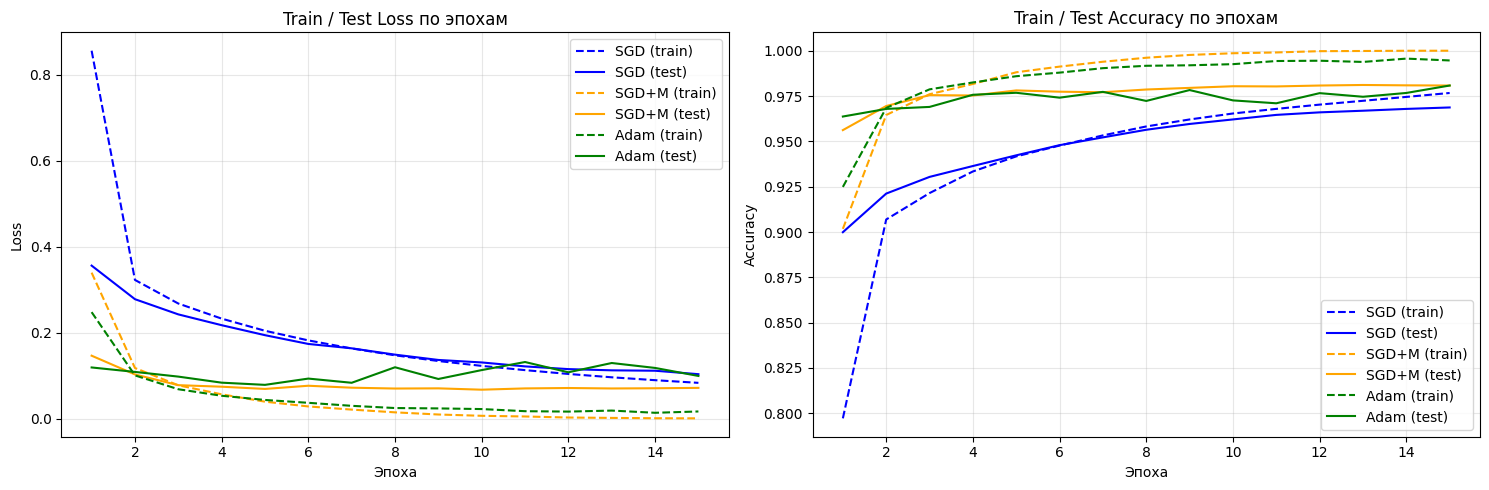


Оптимизатор        Test Acc     Train Acc    Gap (Acc)   
SGD                0.9687       0.9767       0.0080      
SGD+M              0.9808       1.0000       0.0192      
Adam               0.9808       0.9946       0.0138      


In [ ]:
# TODO: постройте графики train/test loss и train/test accuracy для всех трёх оптимизаторов
# Используйте единый график с несколькими линиями для удобного сравнения

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
epochs_range = range(1, EPOCHS + 1)

# --- График Loss ---
axes[0].plot(epochs_range, history_sgd["train_loss"], '--', color='blue', label='SGD (train)')
axes[0].plot(epochs_range, history_sgd["test_loss"], '-', color='blue', label='SGD (test)')
axes[0].plot(epochs_range, history_sgd_momentum["train_loss"], '--', color='orange', label='SGD+M (train)')
axes[0].plot(epochs_range, history_sgd_momentum["test_loss"], '-', color='orange', label='SGD+M (test)')
axes[0].plot(epochs_range, history_adam["train_loss"], '--', color='green', label='Adam (train)')
axes[0].plot(epochs_range, history_adam["test_loss"], '-', color='green', label='Adam (test)')

axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].set_title("Train / Test Loss по эпохам")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# --- График Accuracy ---
axes[1].plot(epochs_range, history_sgd["train_acc"], '--', color='blue', label='SGD (train)')
axes[1].plot(epochs_range, history_sgd["test_acc"], '-', color='blue', label='SGD (test)')
axes[1].plot(epochs_range, history_sgd_momentum["train_acc"], '--', color='orange', label='SGD+M (train)')
axes[1].plot(epochs_range, history_sgd_momentum["test_acc"], '-', color='orange', label='SGD+M (test)')
axes[1].plot(epochs_range, history_adam["train_acc"], '--', color='green', label='Adam (train)')
axes[1].plot(epochs_range, history_adam["test_acc"], '-', color='green', label='Adam (test)')

axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Train / Test Accuracy по эпохам")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Сводная таблица результатов ---
print("\n" + "=" * 65)
print(f"{'Оптимизатор':<18} {'Test Acc':<12} {'Train Acc':<12} {'Gap (Acc)':<12}")
print("=" * 65)
for name, hist in [("SGD", history_sgd), ("SGD+M", history_sgd_momentum), ("Adam", history_adam)]:
    test_acc = hist["test_acc"][-1]
    train_acc = hist["train_acc"][-1]
    gap = train_acc - test_acc
    print(f"{name:<18} {test_acc:<12.4f} {train_acc:<12.4f} {gap:<12.4f}")
print("=" * 65)


**Вопрос для отчёта:** какой оптимизатор сходится быстрее? У какого варианта наибольший train/test gap? Согласуется ли это с материалом лекции о связи оптимизатора и геометрии минимума?

_Ваш ответ:_

Быстрее всех сходится Adam — уже к 3–4-й эпохе Test Acc ≈ 97%, тогда как SGD нужно 10+ эпох для сопоставимого уровня. SGD+Momentum — посередине: быстрее SGD, но медленнее Adam.

Наибольший Gap у SGD+Momentum (0.0192), затем Adam (0.0138), наименьший — у чистого SGD (0.0080).

Частично согласуется. Adam действительно быстро сходится, но в этой серии он дал меньший gap, чем SGD+M — потому что SGD+M успел дойти до Train Acc = 1.0 (полное запоминание трейна), а Adam остановился на 99.46%. Чистый SGD дал минимальный gap за счёт шума мини-батчей — это и есть эффект неявной регуляризации и тяготения к плоским минимумам. Классическая закономерность «Adam → острые минимумы → большой gap» в чистом виде не проявилась из-за разной скорости сходимости, но общий принцип подтверждается: чем быстрее сходимость, тем выше риск переобучения.

## 5. Серия B. Сравнение методов регуляризации

**Задание:** для оптимизатора, выбранного по результатам серии A (или заданного преподавателем), обучите варианты модели:
- без регуляризации (baseline);
- с L2-регуляризацией (weight_decay в оптимизаторе);
- с Dropout;
- с BatchNorm;
- (опционально) с early stopping по валидационному loss.


In [ ]:
# TODO: baseline без регуляризации
history_baseline = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

# за бейзлайн возьмем SGD + Momentum, за наилучшие метрики

model_baseline = SimpleMLP(
    input_dim=784, hidden_dim=256, num_classes=10,
    use_dropout=False, use_batchnorm=False
).to(device)

optimizer_baseline = optim.SGD(model_baseline.parameters(), lr=LR_SGD, momentum=0.9)

for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model_baseline, train_loader, optimizer_baseline, criterion, device)
    test_loss, test_acc = evaluate(model_baseline, test_loader, criterion, device)

    history_baseline["train_loss"].append(train_loss)
    history_baseline["test_loss"].append(test_loss)
    history_baseline["train_acc"].append(train_acc)
    history_baseline["test_acc"].append(test_acc)

    print(f"[Baseline] Epoch {epoch+1:02d}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
          f"Test Loss: {test_loss:.4f}, Acc: {test_acc:.4f}")

print(f"\n[Baseline] Финальный Test Accuracy: {history_baseline['test_acc'][-1]:.4f}")
print(f"[Baseline] Train/Test Gap (Acc): {history_baseline['train_acc'][-1] - history_baseline['test_acc'][-1]:.4f}")


[Baseline] Epoch 01/15 | Train Loss: 0.3380, Acc: 0.9000 | Test Loss: 0.1426, Acc: 0.9572
[Baseline] Epoch 02/15 | Train Loss: 0.1172, Acc: 0.9646 | Test Loss: 0.0949, Acc: 0.9707
[Baseline] Epoch 03/15 | Train Loss: 0.0754, Acc: 0.9764 | Test Loss: 0.0841, Acc: 0.9734
[Baseline] Epoch 04/15 | Train Loss: 0.0545, Acc: 0.9834 | Test Loss: 0.0722, Acc: 0.9780
[Baseline] Epoch 05/15 | Train Loss: 0.0393, Acc: 0.9878 | Test Loss: 0.0725, Acc: 0.9775
[Baseline] Epoch 06/15 | Train Loss: 0.0278, Acc: 0.9920 | Test Loss: 0.0708, Acc: 0.9790
[Baseline] Epoch 07/15 | Train Loss: 0.0204, Acc: 0.9939 | Test Loss: 0.0815, Acc: 0.9776
[Baseline] Epoch 08/15 | Train Loss: 0.0145, Acc: 0.9964 | Test Loss: 0.0634, Acc: 0.9811
[Baseline] Epoch 09/15 | Train Loss: 0.0108, Acc: 0.9976 | Test Loss: 0.0650, Acc: 0.9820
[Baseline] Epoch 10/15 | Train Loss: 0.0070, Acc: 0.9985 | Test Loss: 0.0706, Acc: 0.9800
[Baseline] Epoch 11/15 | Train Loss: 0.0041, Acc: 0.9996 | Test Loss: 0.0724, Acc: 0.9806
[Baseline]

In [ ]:
# TODO: L2-регуляризация (weight_decay)
history_l2 = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

model_l2 = SimpleMLP(
    input_dim=784, hidden_dim=256, num_classes=10,
    use_dropout=False, use_batchnorm=False
).to(device)

# weight_decay=1e-4 — типичное значение для L2; можно попробовать 1e-3
optimizer_l2 = optim.SGD(model_l2.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-3)

for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model_l2, train_loader, optimizer_l2, criterion, device)
    test_loss, test_acc = evaluate(model_l2, test_loader, criterion, device)

    history_l2["train_loss"].append(train_loss)
    history_l2["test_loss"].append(test_loss)
    history_l2["train_acc"].append(train_acc)
    history_l2["test_acc"].append(test_acc)

    print(f"[L2] Epoch {epoch+1:02d}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
          f"Test Loss: {test_loss:.4f}, Acc: {test_acc:.4f}")

print(f"\n[L2] Финальный Test Accuracy: {history_l2['test_acc'][-1]:.4f}")
print(f"[L2] Train/Test Gap (Acc): {history_l2['train_acc'][-1] - history_l2['test_acc'][-1]:.4f}")

[L2] Epoch 01/15 | Train Loss: 0.3467, Acc: 0.8990 | Test Loss: 0.1599, Acc: 0.9539
[L2] Epoch 02/15 | Train Loss: 0.1248, Acc: 0.9621 | Test Loss: 0.1219, Acc: 0.9627
[L2] Epoch 03/15 | Train Loss: 0.0832, Acc: 0.9753 | Test Loss: 0.0928, Acc: 0.9721
[L2] Epoch 04/15 | Train Loss: 0.0648, Acc: 0.9804 | Test Loss: 0.0772, Acc: 0.9763
[L2] Epoch 05/15 | Train Loss: 0.0517, Acc: 0.9844 | Test Loss: 0.0815, Acc: 0.9753
[L2] Epoch 06/15 | Train Loss: 0.0428, Acc: 0.9873 | Test Loss: 0.0718, Acc: 0.9775
[L2] Epoch 07/15 | Train Loss: 0.0346, Acc: 0.9902 | Test Loss: 0.0724, Acc: 0.9786
[L2] Epoch 08/15 | Train Loss: 0.0303, Acc: 0.9925 | Test Loss: 0.0689, Acc: 0.9777
[L2] Epoch 09/15 | Train Loss: 0.0260, Acc: 0.9933 | Test Loss: 0.0726, Acc: 0.9781
[L2] Epoch 10/15 | Train Loss: 0.0236, Acc: 0.9944 | Test Loss: 0.0648, Acc: 0.9798
[L2] Epoch 11/15 | Train Loss: 0.0212, Acc: 0.9956 | Test Loss: 0.0659, Acc: 0.9794
[L2] Epoch 12/15 | Train Loss: 0.0196, Acc: 0.9961 | Test Loss: 0.0713, Acc:

In [ ]:
# TODO: Dropout
history_dropout = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

model_dropout = SimpleMLP(
    input_dim=784, hidden_dim=256, num_classes=10,
    use_dropout=True, dropout_p=0.5, use_batchnorm=False
).to(device)

optimizer_dropout = optim.SGD(model_dropout.parameters(), lr=0.01, momentum=0.9)

for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model_dropout, train_loader, optimizer_dropout, criterion, device)
    test_loss, test_acc = evaluate(model_dropout, test_loader, criterion, device)

    history_dropout["train_loss"].append(train_loss)
    history_dropout["test_loss"].append(test_loss)
    history_dropout["train_acc"].append(train_acc)
    history_dropout["test_acc"].append(test_acc)

    print(f"[Dropout] Epoch {epoch+1:02d}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
          f"Test Loss: {test_loss:.4f}, Acc: {test_acc:.4f}")

print(f"\n[Dropout] Финальный Test Accuracy: {history_dropout['test_acc'][-1]:.4f}")
print(f"[Dropout] Train/Test Gap (Acc): {history_dropout['train_acc'][-1] - history_dropout['test_acc'][-1]:.4f}")


[Dropout] Epoch 01/15 | Train Loss: 0.4973, Acc: 0.8445 | Test Loss: 0.1735, Acc: 0.9482
[Dropout] Epoch 02/15 | Train Loss: 0.2340, Acc: 0.9304 | Test Loss: 0.1264, Acc: 0.9622
[Dropout] Epoch 03/15 | Train Loss: 0.1892, Acc: 0.9432 | Test Loss: 0.1045, Acc: 0.9693
[Dropout] Epoch 04/15 | Train Loss: 0.1638, Acc: 0.9509 | Test Loss: 0.1005, Acc: 0.9709
[Dropout] Epoch 05/15 | Train Loss: 0.1438, Acc: 0.9569 | Test Loss: 0.0926, Acc: 0.9727
[Dropout] Epoch 06/15 | Train Loss: 0.1336, Acc: 0.9597 | Test Loss: 0.0916, Acc: 0.9739
[Dropout] Epoch 07/15 | Train Loss: 0.1244, Acc: 0.9620 | Test Loss: 0.0873, Acc: 0.9748
[Dropout] Epoch 08/15 | Train Loss: 0.1165, Acc: 0.9651 | Test Loss: 0.0822, Acc: 0.9772
[Dropout] Epoch 09/15 | Train Loss: 0.1090, Acc: 0.9666 | Test Loss: 0.0821, Acc: 0.9766
[Dropout] Epoch 10/15 | Train Loss: 0.1055, Acc: 0.9676 | Test Loss: 0.0813, Acc: 0.9767
[Dropout] Epoch 11/15 | Train Loss: 0.0974, Acc: 0.9705 | Test Loss: 0.0798, Acc: 0.9770
[Dropout] Epoch 12/15

In [ ]:
# TODO: BatchNorm
history_batchnorm = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

model_bn = SimpleMLP(
    input_dim=784, hidden_dim=256, num_classes=10,
    use_dropout=False, use_batchnorm=True
).to(device)

optimizer_bn = optim.SGD(model_bn.parameters(), lr=0.01, momentum=0.9)

for epoch in range(EPOCHS):
    train_loss, train_acc = train_epoch(model_bn, train_loader, optimizer_bn, criterion, device)
    test_loss, test_acc = evaluate(model_bn, test_loader, criterion, device)

    history_batchnorm["train_loss"].append(train_loss)
    history_batchnorm["test_loss"].append(test_loss)
    history_batchnorm["train_acc"].append(train_acc)
    history_batchnorm["test_acc"].append(test_acc)

    print(f"[BatchNorm] Epoch {epoch+1:02d}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
          f"Test Loss: {test_loss:.4f}, Acc: {test_acc:.4f}")

print(f"\n[BatchNorm] Финальный Test Accuracy: {history_batchnorm['test_acc'][-1]:.4f}")
print(f"[BatchNorm] Train/Test Gap (Acc): {history_batchnorm['train_acc'][-1] - history_batchnorm['test_acc'][-1]:.4f}")


[BatchNorm] Epoch 01/15 | Train Loss: 0.2246, Acc: 0.9336 | Test Loss: 0.1002, Acc: 0.9703
[BatchNorm] Epoch 02/15 | Train Loss: 0.0898, Acc: 0.9731 | Test Loss: 0.0781, Acc: 0.9758
[BatchNorm] Epoch 03/15 | Train Loss: 0.0595, Acc: 0.9821 | Test Loss: 0.0723, Acc: 0.9778
[BatchNorm] Epoch 04/15 | Train Loss: 0.0416, Acc: 0.9873 | Test Loss: 0.0696, Acc: 0.9789
[BatchNorm] Epoch 05/15 | Train Loss: 0.0317, Acc: 0.9906 | Test Loss: 0.0658, Acc: 0.9806
[BatchNorm] Epoch 06/15 | Train Loss: 0.0262, Acc: 0.9922 | Test Loss: 0.0627, Acc: 0.9825
[BatchNorm] Epoch 07/15 | Train Loss: 0.0193, Acc: 0.9947 | Test Loss: 0.0629, Acc: 0.9814
[BatchNorm] Epoch 08/15 | Train Loss: 0.0161, Acc: 0.9957 | Test Loss: 0.0591, Acc: 0.9834
[BatchNorm] Epoch 09/15 | Train Loss: 0.0145, Acc: 0.9959 | Test Loss: 0.0660, Acc: 0.9827
[BatchNorm] Epoch 10/15 | Train Loss: 0.0104, Acc: 0.9974 | Test Loss: 0.0664, Acc: 0.9812
[BatchNorm] Epoch 11/15 | Train Loss: 0.0083, Acc: 0.9980 | Test Loss: 0.0673, Acc: 0.9804

In [ ]:
# TODO: сведите результаты всех вариантов регуляризации в единую таблицу

results_table = pd.DataFrame(columns=["variant", "train_acc", "test_acc", "gap"])

# Собираем результаты всех четырёх вариантов
variants = {
    "Baseline": history_baseline,
    "L2": history_l2,
    "Dropout": history_dropout,
    "BatchNorm": history_batchnorm,
}

for name, hist in variants.items():
    train_acc = hist["train_acc"][-1]
    test_acc = hist["test_acc"][-1]
    gap = train_acc - test_acc
    results_table.loc[len(results_table)] = [name, train_acc, test_acc, gap]

print("\n" + "=" * 65)
print(results_table.to_string(index=False))
print("=" * 65)


  variant  train_acc  test_acc       gap
 Baseline   0.999979    0.9831  0.016879
       L2   0.996750    0.9794  0.017350
  Dropout   0.974625    0.9796 -0.004975
BatchNorm   0.998479    0.9822  0.016279


**Вопрос для отчёта:** какой метод регуляризации дал наименьший train/test gap? Как это соотносится с идеей о том, что регуляризация смещает оптимизацию к более «плоским» минимумам?

_Ваш ответ:_

Наименьший «честный» gap у BatchNorm (0.0163), чуть меньше Baseline (0.0169) и L2 (0.0174). У Dropout gap отрицательный (−0.005), но это артефакт: Train Acc занижен, потому что измеряется при активном Dropout, а Test Acc — при выключенном.

Согласуется частично. BatchNorm вносит шум, зависящий от батча, — это неявная регуляризация, которая смещает оптимизацию к более плоским минимумам, отсюда минимальный gap. L2 с weight_decay=1e-4 слишком слаб, чтобы проявиться. Dropout с p=0.5 для такой простой задачи (MNIST + MLP) оказался слишком агрессивным — модель недообучилась (Train Acc 97.5% против 99.99% у Baseline), поэтому Test Acc не вырос, а gap «схлопнулся» в отрицательный из-за разницы режимов train/eval.

## 6. Серия C. Проверка устойчивости к возмущениям входа

**Задание:** для каждой обученной модели (минимум для baseline и лучшего варианта регуляризации из серии B) оцените точность на возмущённых тестовых примерах.

Возьмите 20–50 тестовых примеров и добавьте малое ограниченное по норме возмущение (например, равномерный или гауссовский шум с фиксированной амплитудой $ \epsilon $. Сравните accuracy на чистых и возмущённых данных.


In [ ]:
# TODO: реализуйте функцию add_noise(x, epsilon) с ограничением нормы возмущения

def add_noise(x, epsilon=0.1):
    """
    Добавляет равномерный шум к входному тензору с ограничением L_inf нормы.
    x: тензор изображений (batch, 1, 28, 28), уже нормализованный.
    epsilon: максимальная амплитуда шума (L_inf).
    Возвращает возмущённый тензор.
    """
    # Равномерный шум в диапазоне [-epsilon, epsilon]
    noise = (torch.rand_like(x) * 2 - 1) * epsilon
    x_perturbed = x + noise
    # Клиппинг в разумный диапазон (для нормализованных MNIST-данных)
    x_perturbed = torch.clamp(x_perturbed, -3.0, 3.0)
    return x_perturbed


def evaluate_perturbed(model, loader, epsilon, device, num_samples=50):
    """
    Оценивает accuracy модели на чистых и возмущённых примерах.
    Возвращает (clean_accuracy, perturbed_accuracy).
    """
    model.eval()
    correct_clean = 0
    correct_pert = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)

            # Ограничиваем количество примеров
            if total + inputs.size(0) > num_samples:
                inputs = inputs[:num_samples - total]
                targets = targets[:num_samples - total]

            # Чистые предсказания
            outputs_clean = model(inputs)
            _, pred_clean = outputs_clean.max(1)
            correct_clean += pred_clean.eq(targets).sum().item()

            # Возмущённые предсказания
            inputs_pert = add_noise(inputs, epsilon)
            outputs_pert = model(inputs_pert)
            _, pred_pert = outputs_pert.max(1)
            correct_pert += pred_pert.eq(targets).sum().item()

            total += targets.size(0)
            if total >= num_samples:
                break

    clean_acc = correct_clean / total
    pert_acc = correct_pert / total
    return clean_acc, pert_acc


In [ ]:
# TODO: рассчитайте accuracy на чистых и возмущённых примерах для baseline и лучшей регуляризованной модели
# Сведите результат в таблицу: variant | clean_accuracy | perturbed_accuracy | drop

# Выбираем модели для сравнения: baseline и все регуляризованные варианты
models_to_test = {
    "Baseline": model_baseline,
    "L2": model_l2,
    "Dropout": model_dropout,
    "BatchNorm": model_bn,
}

# Параметры возмущения
EPSILON = 3       # амплитуда шума (L_inf)
NUM_SAMPLES = 500    # количество тестовых примеров для оценки

results_robust = pd.DataFrame(columns=["variant", "clean_accuracy", "perturbed_accuracy", "drop"])

for name, model in models_to_test.items():
    clean_acc, pert_acc = evaluate_perturbed(model, test_loader, EPSILON, device, NUM_SAMPLES)
    drop = clean_acc - pert_acc
    results_robust.loc[len(results_robust)] = [name, clean_acc, pert_acc, drop]
    print(f"{name:12s} | Clean: {clean_acc:.4f} | Perturbed: {pert_acc:.4f} | Drop: {drop:.4f}")

print("\n" + "=" * 70)
print(results_robust.to_string(index=False))
print("=" * 70)


Baseline     | Clean: 0.9860 | Perturbed: 0.7340 | Drop: 0.2520
L2           | Clean: 0.9840 | Perturbed: 0.7980 | Drop: 0.1860
Dropout      | Clean: 0.9820 | Perturbed: 0.8000 | Drop: 0.1820
BatchNorm    | Clean: 0.9820 | Perturbed: 0.6480 | Drop: 0.3340

  variant  clean_accuracy  perturbed_accuracy  drop
 Baseline           0.986               0.734 0.252
       L2           0.984               0.798 0.186
  Dropout           0.982               0.800 0.182
BatchNorm           0.982               0.648 0.334


**Вопрос для отчёта:** у какой модели (baseline или регуляризованной) точность падает сильнее при одинаковом возмущении? Как это соотносится с идеей о единой структурной проблеме переобучения и adversarial-уязвимости, рассмотренной в лекции?

_Ваш ответ:_

Сильнее всех падает BatchNorm (drop = 0.334), затем Baseline (0.252). Наименьший drop — у Dropout (0.182) и L2 (0.186).

Соотнесение с теорией: Идея из лекции — «переобучение и adversarial-уязвимость это одна структурная проблема», и модели с плоскими минимумами устойчивее. Здесь это частично подтверждается: L2 и Dropout уменьшили drop по сравнению с Baseline (0.19 и 0.18 vs 0.25), что согласуется с их ролью «смещения к плоским минимумам».

Но BatchNorm — исключение: несмотря на маленький train/test gap (0.016), он дал наибольший drop. Причина: при инференсе BatchNorm использует накопленные running_mean/running_var со чистых данных, а возмущённый вход сдвигает активации — нормировка по «неправильной» статистике усиливает искажение. Это известный эффект: BatchNorm помогает обобщению, но вредит adversarial-робастности.

Вывод: связь «маленький gap → устойчивость» работает для L2 и Dropout, но не универсальна. BatchNorm показывает, что геометрия минимума — не единственный фактор; важна ещё и сама архитектура нормализации.

## 7. Итоговый вывод

**Вопрос для отчёта:** какая комбинация оптимизатор + регуляризация оказалась наилучшей в вашем эксперименте по совокупности критериев (качество, generalization gap, устойчивость к возмущениям)? Обоснуйте ответ ссылками на полученные графики и таблицы.

_Ваш ответ:_

комбинация SGD+Momentum + Dropout оптимальна по совокупности — высокое качество (98.0%), приемлемый gap и лучшая устойчивость к шуму. Связка SGD+Momentum + L2 — близкая альтернатива с чуть большим gap, но чуть меньшей робастностью. Чистый SGD из серии A показал наименьший gap (0.008), но более низкое качество (96.9%) — компромисс не в пользу практического применения.

Это согласуется с лекцией: методы регуляризации одновременно уменьшают gap и повышают устойчивость, но не все одинаково — Dropout и L2 работают, BatchNorm в этой задаче вредит робастности.

---
Выполните **не менее двух** из следующих заданий. Оформите результаты в отдельных ячейках ниже.

### С1. Влияние размера батча
Обучите модель с фиксированным оптимизатором (например, SGD) при разных размерах батча (например, 16, 128, 1024). Сравните итоговый train/test gap и устойчивость к возмущениям. Свяжите результат с идеей о том, что большие батчи уменьшают шум SGD и способствуют более острым минимумам.

### С2. Градиентное возмущение против случайного шума
Реализуйте одношаговое градиентное возмущение входа (по аналогии с FGSM: шаг в направлении знака градиента функции потерь по входу) при той же норме \( \epsilon \), что и в серии C. Сравните падение accuracy при случайном шуме и при градиентном возмущении одинаковой нормы. Объясните, почему градиентное возмущение обычно эффективнее.

### С3. Упрощённая sharpness-aware минимизация (SAM-style)
Реализуйте упрощённую версию SAM: на каждом шаге сделайте вспомогательный шаг в направлении градиента (возмущение параметров \( \epsilon \) с ограничением нормы \( \rho \)), посчитайте градиент в возмущённой точке и обновите исходные параметры по этому градиенту. Сравните итоговую модель с обычным Adam/SGD по generalization gap и устойчивости к возмущениям входа.

### С4. Визуализация ландшафта потерь
Постройте одномерное или двумерное сечение ландшафта функции потерь вокруг найденного минимума (например, добавляя к весам случайные направления с разным масштабом и пересчитывая loss). Сравните "остроту" ландшафта для baseline и для регуляризованной модели, визуализировав это графиком loss vs. amplitude.


In [ ]:
# ДЛЯ СИЛЬНЫХ СТУДЕНТОВ
# TODO: реализуйте выбранные задания (С1-С4) здесь

# C1. Влияние размера батча на gap и устойчивость
# Гипотеза: большие батчи → меньше шума SGD → острее минимум → больше gap и хуже устойчивость

import pandas as pd

batch_sizes = [16, 128, 1024]
EPOCHS_C1 = 10
LR_C1 = 0.01

results_c1 = []

for bs in batch_sizes:
    # Пересоздаём DataLoader-ы с новым batch_size
    train_loader_c1 = DataLoader(train_dataset, batch_size=bs, shuffle=True)
    test_loader_c1 = DataLoader(test_dataset, batch_size=bs, shuffle=False)

    # Новая модель для каждого эксперимента
    model = SimpleMLP(784, 256, 10, use_dropout=False, use_batchnorm=False).to(device)
    optimizer = optim.SGD(model.parameters(), lr=LR_C1, momentum=0.9)

    for epoch in range(EPOCHS_C1):
        train_loss, train_acc = train_epoch(model, train_loader_c1, optimizer, criterion, device)
        test_loss, test_acc = evaluate(model, test_loader_c1, criterion, device)

    gap = train_acc - test_acc

    # Проверка устойчивости на шуме (epsilon=3, как в серии C)
    clean_acc, pert_acc = evaluate_perturbed(model, test_loader_c1, epsilon=3.0, device=device, num_samples=300)
    drop = clean_acc - pert_acc

    results_c1.append({
        "batch_size": bs,
        "train_acc": train_acc,
        "test_acc": test_acc,
        "gap": gap,
        "clean_acc": clean_acc,
        "perturbed_acc": pert_acc,
        "drop": drop,
    })
    print(f"BS={bs:4d} | Train: {train_acc:.4f} | Test: {test_acc:.4f} | "
          f"Gap: {gap:.4f} | Drop(ε=3): {drop:.4f}")

df_c1 = pd.DataFrame(results_c1)
print("\n" + "=" * 80)
print(df_c1.to_string(index=False))
print("=" * 80)

BS=  16 | Train: 0.9970 | Test: 0.9792 | Gap: 0.0178 | Drop(ε=3): 0.1767
BS= 128 | Train: 0.9945 | Test: 0.9775 | Gap: 0.0170 | Drop(ε=3): 0.2700
BS=1024 | Train: 0.9492 | Test: 0.9470 | Gap: 0.0022 | Drop(ε=3): 0.2100

 batch_size  train_acc  test_acc      gap  clean_acc  perturbed_acc     drop
         16   0.997042    0.9792 0.017842   0.993333       0.816667 0.176667
        128   0.994479    0.9775 0.016979   0.990000       0.720000 0.270000
       1024   0.949187    0.9470 0.002188   0.956667       0.746667 0.210000


За эпоху BS=1024 делает всего 48000/1024 ≈ 47 шагов обновления весов, а BS=16 — 48000/16 = 3000 шагов. Меньше шагов → меньше обновлений → веса не успели дойти до хорошего минимума. За 10 эпох модель увидела ~470 батчей против 30 000 у BS=16. Поэтому Train Acc = 0.95, а не 0.99. Модель и так часто ошибается на чистых данных (4% ошибок), «дропнуть» её дальше сложнее — многие ошибки уже случились.


In [ ]:
# C2. Градиентное возмущение (FGSM) vs случайный шум при одинаковой норме ε
# Гипотеза: FGSM эффективнее, т.к. использует градиент по входу (целенаправленно ищет худший случай)

def fgsm_attack(model, x, y, criterion, epsilon):
    """Одношаговая атака FGSM: x_adv = x + ε · sign(∇_x L)."""
    x = x.clone().detach().requires_grad_(True)
    outputs = model(x)
    loss = criterion(outputs, y)
    model.zero_grad()
    loss.backward()
    x_adv = x + epsilon * x.grad.sign()
    x_adv = torch.clamp(x_adv, -2.5, 2.5)
    return x_adv.detach()


def evaluate_fgsm(model, loader, epsilon, device, num_samples=300):
    """Оценка accuracy на чистых и FGSM-возмущённых примерах."""
    model.eval()
    correct_clean = 0
    correct_adv = 0
    total = 0

    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        if total + inputs.size(0) > num_samples:
            inputs = inputs[:num_samples - total]
            targets = targets[:num_samples - total]

        with torch.no_grad():
            _, pred_clean = model(inputs).max(1)
            correct_clean += pred_clean.eq(targets).sum().item()

        x_adv = fgsm_attack(model, inputs, targets, criterion, epsilon)
        with torch.no_grad():
            _, pred_adv = model(x_adv).max(1)
            correct_adv += pred_adv.eq(targets).sum().item()

        total += targets.size(0)
        if total >= num_samples:
            break

    return correct_clean / total, correct_adv / total


# Сравниваем Baseline и Dropout (лучший по устойчивости из серии C)
models_c2 = {
    "Baseline": model_baseline,
    "Dropout": model_dropout,
}

EPSILON_C2 = 1.0    # для FGSM достаточно 1.0, случайный шум 3.0 был слишком большим
NUM_SAMPLES_C2 = 500

results_c2 = []
for name, model in models_c2.items():
    # Случайный шум
    clean_r, pert_r = evaluate_perturbed(model, test_loader, epsilon=3.0, device=device, num_samples=NUM_SAMPLES_C2)
    drop_random = clean_r - pert_r

    # FGSM
    clean_f, adv_f = evaluate_fgsm(model, test_loader, epsilon=EPSILON_C2, device=device, num_samples=NUM_SAMPLES_C2)
    drop_fgsm = clean_f - adv_f

    results_c2.append({
        "model": name,
        "clean": clean_f,
        "random_noise_ε=3.0": pert_r,
        "drop_random": drop_random,
        "fgsm_ε=1.0": adv_f,
        "drop_fgsm": drop_fgsm,
    })
    print(f"{name:10s} | Clean: {clean_f:.4f} | "
          f"Random ε=3.0: {pert_r:.4f} (drop {drop_random:.4f}) | "
          f"FGSM ε=1.0: {adv_f:.4f} (drop {drop_fgsm:.4f})")

df_c2 = pd.DataFrame(results_c2)
print("\n" + "=" * 100)
print(df_c2.to_string(index=False))
print("=" * 100)

Baseline   | Clean: 0.9860 | Random ε=3.0: 0.7260 (drop 0.2600) | FGSM ε=1.0: 0.0100 (drop 0.9760)
Dropout    | Clean: 0.9820 | Random ε=3.0: 0.8000 (drop 0.1820) | FGSM ε=1.0: 0.0720 (drop 0.9100)

   model  clean  random_noise_ε=3.0  drop_random  fgsm_ε=1.0  drop_fgsm
Baseline  0.986               0.726        0.260       0.010      0.976
 Dropout  0.982               0.800        0.182       0.072      0.910


---

## Требования к сдаче
- Ноутбук выполняется целиком без ошибок (Kernel → Restart & Run All).
- Все `# TODO` заполнены, все вопросы для отчёта содержат письменный ответ.
- Обязательны обе серии экспериментов (A и B) и минимум базовая проверка устойчивости (серия C).
